# Proyecto II: Detección de anomalías industriales mediante destilado de modelos y autoencoders

**Curso:** Inteligencia Artificial, Escuela de Ingeniería en Computación, Instituto Tecnológico de Costa Rica

**Integrantes:**
- Sebastián Chacón - 2023221908
- Daniel Pulido - 2019196502
- Sebastián Muñoz - 2023090681

**Notebook 2 de 4: modelos A y B.** Entrenar el clasificador CNN con la estructura de ResNet-18 hasta `conv3_x`, desde cero (modelo A) y por destilado teacher student a partir de un ResNet-18 completo (modelo B), con al menos 3 combinaciones de hiperparámetros cada uno.

El proyecto se divide en cuatro notebooks que comparten la configuración de `conf/` y el código de `src/`:
1. `datos.ipynb`: exploración de MVTec AD y `LightningDataModule`.
2. `modelos_ab.ipynb`: modelo A (CNN desde cero) y modelo B (CNN destilada).
3. `modelo_c.ipynb`: modelo C (autoencoder U-Net).
4. `anomalias.ipynb`: detección de anomalías con embeddings y análisis con DBSCAN.

## Contenido
1. Configuración y entorno
2. Modelo A, CNN desde cero
3. Modelo B, CNN destilada
4. Comparación de los modelos A y B

## 1. Configuración y entorno

### 1.1 Imports y configuración con Hydra
Las clases (DataModule, modelos y utilidades de entrenamiento) están en `src/` como scripts auxiliares, y este notebook las importa y ejecuta. Para eso se agrega la raíz del repositorio a `sys.path`. Con `autoreload` los cambios en `src/` se cargan sin reiniciar el kernel.

El decorador `@hydra.main` está pensado para scripts que se ejecutan desde la terminal y no funciona dentro de Jupyter. Por eso `load_config` usa la API de composición de Hydra (`initialize_config_dir` y `compose`), que es la que recomienda su documentación para notebooks. Recibe una lista de overrides, por ejemplo `["+experiment=cnn_scratch/lr3e-4_bs32"]`, y así cada corrida varía sus hiperparámetros sin tocar los archivos YAML.

In [1]:
# Imports, repository root and Hydra configuration
%load_ext autoreload
%autoreload 2

import logging
import sys
import warnings
from pathlib import Path

# Hide noise that does not affect the results: torch's "triton not found" (no triton on Windows)
logging.getLogger("torch.utils.flop_counter").setLevel(logging.ERROR)
warnings.filterwarnings("ignore", category=FutureWarning)
warnings.filterwarnings("ignore", category=DeprecationWarning)

# The notebook lives in notebooks/, the repository root is its parent folder
PROJECT_ROOT = Path.cwd().resolve().parent
assert (PROJECT_ROOT / "conf").is_dir(), "Run the notebook from the notebooks/ folder"
if str(PROJECT_ROOT) not in sys.path:
    sys.path.insert(0, str(PROJECT_ROOT))

import lightning as L
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import torch
import wandb
from hydra.utils import instantiate
from omegaconf import OmegaConf

from src.utils import load_config, resolve_path

cfg = load_config()
print(OmegaConf.to_yaml(cfg))

data:
  _target_: src.data.MVTecDataModule
  _convert_: all
  root: data/mvtec_ad
  categories:
  - carpet
  - leather
  - tile
  - wood
  - bottle
  - cable
  - capsule
  - hazelnut
  - metal_nut
  - pill
  image_size: 224
  batch_size: 32
  num_workers: 0
  cache_dir: ${paths.output_dir}/cache
  val_split: 0.2
  seed: ${seed}
  mean:
  - 0.485
  - 0.456
  - 0.406
  std:
  - 0.229
  - 0.224
  - 0.225
model:
  _target_: src.models.cnn.CNNClassifierModule
  _convert_: all
  name: cnn_scratch
  num_classes: ${len:${data.categories}}
  z_dim: null
  head:
    hidden_dim: 256
    dropout: 0.3
  optimizer:
    _target_: torch.optim.AdamW
    _partial_: true
    lr: 0.001
    weight_decay: 0.0001
  scheduler: null
trainer:
  _target_: lightning.Trainer
  max_epochs: 50
  accelerator: auto
  devices: 1
  precision: 16-mixed
  log_every_n_steps: 10
  enable_progress_bar: false
callbacks:
  early_stopping:
    _target_: lightning.pytorch.callbacks.EarlyStopping
    monitor: val/loss
    mode: m

### 1.2 Semilla y GPU
Se fija la semilla de Python, NumPy y PyTorch para que los resultados sean reproducibles, y se verifica que la GPU esté disponible.

In [2]:
# Seed, GPU and library versions
L.seed_everything(cfg.seed)
# Lets float32 matrix multiplications use the GPU Tensor Cores (TF32): faster, negligible precision change
torch.set_float32_matmul_precision("high")

print("PyTorch", torch.__version__, "| Lightning", L.__version__, "| wandb", wandb.__version__)
print("CUDA disponible:", torch.cuda.is_available())
if torch.cuda.is_available():
    props = torch.cuda.get_device_properties(0)
    print(f"GPU: {props.name}, {props.total_memory / 1024**3:.1f} GB de VRAM")

Seed set to 42


PyTorch 2.14.1+cu130 | Lightning 2.6.6 | wandb 0.31.2
CUDA disponible: True
GPU: NVIDIA GeForce RTX 4060, 8.0 GB de VRAM


### 1.3 Datos
Se construye el `MVTecDataModule` desde `conf/data/mvtec.yaml` (está descrito y verificado en `datos.ipynb`). Aquí se usa un batch de entrenamiento para comprobar las formas de cada etapa de la red.

In [3]:
# DataModule and one training batch to check the shapes of the network
datamodule = instantiate(cfg.data)
datamodule.prepare_data()
datamodule.setup()
categories = datamodule.categories
batch = next(iter(datamodule.train_dataloader()))
print(f"train {len(datamodule.train_set)} | val {len(datamodule.val_set)} | test {len(datamodule.test_set)}")
print("batch:", tuple(batch["image"].shape), "| categorias:", categories)

train 2025 | val 507 | test 1194
batch: (32, 3, 224, 224) | categorias: ['carpet', 'leather', 'tile', 'wood', 'bottle', 'cable', 'capsule', 'hazelnut', 'metal_nut', 'pill']


## 2. Modelo A, CNN desde cero

Código en `src/models/cnn.py`, configuración en `conf/model/cnn_scratch.yaml` y combinaciones en `conf/experiment/cnn_scratch/`.

### 2.1 Backbone: ResNet-18 hasta `conv3_x`
El enunciado pide seguir la estructura de ResNet-18 en sus tres primeras etapas (Figura 1 del enunciado):

| Etapa | Capas | Salida con entrada 224×224 |
|---|---|---|
| `conv1` | conv 7×7, 64 filtros, stride 2 + BatchNorm + ReLU | 64 × 112 × 112 |
| `conv2_x` | max pool 3×3 stride 2 + 2 bloques residuales [3×3, 64; 3×3, 64] | 64 × 56 × 56 |
| `conv3_x` | 2 bloques residuales [3×3, 128; 3×3, 128], el primero con stride 2 | 128 × 28 × 28 |

En lugar de reescribir esas capas se toman del `resnet18` de torchvision con `weights=None`. Así la estructura es idéntica a la del ResNet-18 que hará de teacher en el modelo B (en torchvision `conv2_x` es `maxpool + layer1` y `conv3_x` es `layer2`), y con `weights=None` los pesos empiezan aleatorios (inicialización de Kaiming), como pide el enunciado para el modelo A. La clase `ResNet18Stem` expone además `forward_features`, que devuelve la salida de cada etapa. El modelo A no la usa, pero el modelo B la necesita para comparar sus features con las del teacher.

In [4]:
# Output shape of each stage of the backbone
from src.models.cnn import CNNClassifier, CNNClassifierModule, ResNet18Stem

stem = ResNet18Stem()
with torch.no_grad():
    features = stem.forward_features(batch["image"][:4])
print(f"{'entrada':8s} {tuple(batch['image'][:4].shape)}")
for name, f in features.items():
    print(f"{name:8s} {tuple(f.shape)}")

entrada  (4, 3, 224, 224)
conv1    (4, 64, 112, 112)
conv2_x  (4, 64, 56, 56)
conv3_x  (4, 128, 28, 28)


### 2.2 Clasificador y `get_embedding`
Después de `conv3_x` se aplica *global average pooling*, que promedia cada uno de los 128 canales sobre las 28×28 posiciones. Ese vector de 128 valores es el **embedding** del modelo. Es la salida de las capas convolucionales que pide el enunciado y sobre él se construye el detector de anomalías. El método `get_embedding(x)` lo devuelve directamente.

El clasificador es una cabeza FC de diseño libre: `128 -> hidden_dim -> 10` con ReLU y dropout. La capa oculta le da a la cabeza capacidad para separar las categorías sin forzar al embedding a ser linealmente separable, y el dropout reduce el sobreajuste en un conjunto de unas 2000 imágenes. El embedding se toma **antes** del clasificador para que no dependa de la tarea de clasificación más de lo necesario.

La tarea de clasificar la categoría es fácil a propósito. Su función es obligar al backbone a aprender representaciones de las imágenes normales, y por eso el accuracy no es la métrica principal del proyecto. Lo que importa es qué tan útil es el embedding para separar lo normal de lo anómalo, y eso se mide en `anomalias.ipynb`.

La configuración tiene además `z_dim` (por defecto `null`). Con un número agrega una proyección lineal `128 -> z_dim` y el embedding se toma después de ella. Así la dimensión del embedding también se puede variar desde Hydra.

In [5]:
# Embedding and logits shapes, and number of parameters against a full ResNet-18
from torchvision.models import resnet18

from src.reporting import count_parameters

cfg_a = load_config(["+experiment=cnn_scratch/lr1e-3_bs32"])
net = CNNClassifier(num_classes=len(categories), z_dim=cfg_a.model.z_dim, **cfg_a.model.head)
with torch.no_grad():
    x = batch["image"][:4]
    print("embedding:", tuple(net.get_embedding(x).shape), "| logits:", tuple(net(x).shape))

resnet_params = count_parameters(resnet18(weights=None))
params = pd.Series({
    "backbone (conv1 a conv3_x)": count_parameters(net.backbone),
    "clasificador FC": count_parameters(net.head),
    "modelo A completo": count_parameters(net),
    "ResNet-18 completo (referencia)": resnet_params,
}, name="parametros").to_frame()
params["millones"] = (params["parametros"] / 1e6).round(3)
params["% de ResNet-18"] = (100 * params["parametros"] / resnet_params).round(1)
params

embedding: (4, 128) | logits: (4, 10)


,parametros,millones,% de ResNet-18
backbone (conv1 a conv3_x),683072,0.683,5.8
clasificador FC,35594,0.036,0.3
modelo A completo,718666,0.719,6.1
ResNet-18 completo (referencia),11689512,11.690,100.0


### 2.3 `LightningModule`
`CNNClassifierModule` envuelve la red y define el entrenamiento:

- **`training_step`, `validation_step` y `test_step`** llaman a un `shared_step` común, que calcula la entropía cruzada entre los logits y la categoría de la imagen y registra `<split>/loss` y `<split>/acc` por época. Las tres etapas usan exactamente el mismo cálculo y solo cambia el prefijo.
- **`configure_optimizers`** construye el optimizador y el scheduler opcional a partir de los objetos parciales que crea Hydra (`_partial_: true`), porque los parámetros del modelo solo existen en ese momento.
- **`save_hyperparameters(logger=False)`** guarda la configuración del modelo dentro del checkpoint. No se envía al logger porque `run_experiment` ya registra en W&B la configuración completa de Hydra.

El módulo se construye con `instantiate(cfg.model)`, que lee el `_target_` de `conf/model/cnn_scratch.yaml` y le pasa el resto de las llaves como argumentos.

In [6]:
# Model A built from its Hydra config
model_a = instantiate(cfg_a.model)
print(L.pytorch.utilities.model_summary.ModelSummary(model_a, max_depth=3))

   | Name                 | Type              | Params | Mode  | FLOPs
----------------------------------------------------------------------------
0  | net                  | CNNClassifier     | 718 K  | train | 0    
1  | net.backbone         | ResNet18Stem      | 683 K  | train | 0    
2  | net.backbone.conv1   | Sequential        | 9.5 K  | train | 0    
3  | net.backbone.conv2_x | Sequential        | 147 K  | train | 0    
4  | net.backbone.conv3_x | Sequential        | 525 K  | train | 0    
5  | net.pool             | AdaptiveAvgPool2d | 0      | train | 0    
6  | net.projection       | Identity          | 0      | train | 0    
7  | net.head             | Sequential        | 35.6 K | train | 0    
8  | net.head.0           | Linear            | 33.0 K | train | 0    
9  | net.head.1           | ReLU              | 0      | train | 0    
10 | net.head.2           | Dropout           | 0      | train | 0    
11 | net.head.3           | Linear            | 2.6 K  | train | 0    


### 2.4 Combinaciones de hiperparámetros
El enunciado pide entrenar cada modelo con al menos 3 combinaciones de hiperparámetros. Cada una es un archivo de `conf/experiment/cnn_scratch/` que parte de `conf/model/cnn_scratch.yaml` y cambia solo lo que la distingue:

- **`A-cnn_scratch-lr1e-3_bs32`:** AdamW con learning rate constante de 1e-3 y batch de 32. Es el punto de referencia.
- **`A-cnn_scratch-lr3e-4_bs32`:** igual que la anterior pero con learning rate de 3e-4. Pasos más pequeños y estables, para aislar el efecto del learning rate.
- **`A-cnn_scratch-lr1e-3cos_bs64`:** batch de 64 (gradientes menos ruidosos y la mitad de pasos por época) y learning rate que baja de 1e-3 a 1e-5 siguiendo un coseno durante 20 épocas, con pasos grandes al inicio y ajustes finos al final.

Todas usan `EarlyStopping` sobre `val/loss` con paciencia de 5 épocas y guardan el checkpoint con la menor `val/loss`. El nombre de cada corrida sigue el formato `<letra del modelo>-<modelo>-<hiperparámetros>`, y es el mismo en W&B, en la carpeta del checkpoint y en el archivo de resultados. En W&B las corridas se agrupan por modelo (`group`), llevan la descripción como nota y tienen un tag por hiperparámetro (`lr=3e-4`, `bs=32`, `lr_coseno`) para filtrarlas. La tabla muestra los valores efectivos de cada combinación, tal como los compone Hydra.

In [7]:
# Effective hyperparameters of each combination (composed with Hydra)
EXPERIMENTS_A = ["cnn_scratch/lr1e-3_bs32", "cnn_scratch/lr3e-4_bs32", "cnn_scratch/lr1e-3cos_bs64"]


def hyperparameters_table(experiments):
    rows = []
    for experiment in experiments:
        c = load_config([f"+experiment={experiment}"])
        scheduler = c.model.get("scheduler")
        lr = c.model.optimizer.lr
        rows.append({
            "corrida": c.name,
            "batch": c.data.batch_size,
            "lr": f"{lr} -> {scheduler.eta_min} (coseno)" if scheduler else f"{lr} (constante)",
            "weight decay": c.model.optimizer.weight_decay,
            "z_dim": c.model.z_dim or "128 (sin proyeccion)",
            "capa oculta": c.model.head.hidden_dim,
            "dropout": c.model.head.dropout,
            "max epocas": c.trainer.max_epochs,
            "paciencia": c.callbacks.early_stopping.patience,
            "tags W&B": ", ".join(c.tags),
            "descripcion": c.description,
        })
    return pd.DataFrame(rows).set_index("corrida")


hyperparameters_table(EXPERIMENTS_A)

,batch,lr,weight decay,z_dim,capa oculta,dropout,max epocas,paciencia,tags W&B,descripcion
corrida,,,,,,,,,,
A-cnn_scratch-lr1e-3_bs32,32,0.001 (constante),0.0001,128 (sin proyeccion),256,0.3,50,5,"A, cnn_scratch, lr=1e-3, bs=32, lr_constante","Modelo A, AdamW lr 1e-3 constante, batch 32"
A-cnn_scratch-lr3e-4_bs32,32,0.0003 (constante),0.0001,128 (sin proyeccion),256,0.3,50,5,"A, cnn_scratch, lr=3e-4, bs=32, lr_constante","Modelo A, AdamW lr 3e-4 constante, batch 32"
A-cnn_scratch-lr1e-3cos_bs64,64,0.001 -> 1e-05 (coseno),0.0001,128 (sin proyeccion),256,0.3,20,5,"A, cnn_scratch, lr=1e-3, bs=64, lr_coseno","Modelo A, AdamW lr coseno 1e-3 -> 1e-5 en 20 e..."


### 2.5 Prueba rápida
Antes de entrenar se ejecuta un `fast_dev_run`: un batch de entrenamiento y uno de validación, sin logger ni checkpoints. Sirve para detectar errores de forma o de configuración en segundos, antes de crear corridas en W&B.

In [8]:
# fast_dev_run: one training and one validation batch, without logger or checkpoints
from src.training import build_callbacks, build_trainer, run_experiment

smoke_cfg = load_config(["+experiment=cnn_scratch/lr1e-3_bs32", "+trainer.fast_dev_run=true"])
smoke_callbacks = {k: v for k, v in build_callbacks(smoke_cfg).items() if k != "lr_monitor"}
build_trainer(smoke_cfg, smoke_callbacks).fit(instantiate(smoke_cfg.model), datamodule=datamodule)
print("fast_dev_run OK")

Using 16bit Automatic Mixed Precision (AMP)
GPU available: True (cuda), used: True
TPU available: False, using: 0 TPU cores
💡 Tip: For seamless cloud logging and experiment tracking, try installing [litlogger](https://pypi.org/project/litlogger/) to enable LitLogger, which logs metrics and artifacts automatically to the Lightning Experiments platform.
Running in `fast_dev_run` mode: will run the requested loop using 1 batch(es). Logging and checkpointing is suppressed.
LOCAL_RANK: 0 - CUDA_VISIBLE_DEVICES: [0]
c:\Users\Chaco\OneDrive\Documents\GitHub\MVTecDestilado\.venv\Lib\site-packages\lightning\pytorch\utilities\model_summary\model_summary.py:242: Precision 16-mixed is not supported by the model summary.  Estimated model size in MB will not be accurate. Using 32 bits instead.

  | Name | Type          | Params | Mode  | FLOPs
-------------------------------------------------------
0 | net  | CNNClassifier | 718 K  | train | 0    
----------------------------------------------------

epoca   1 | train/acc 0.1250 | train/loss 2.3191 | val/acc 1.0000 | val/loss 1.8779


`Trainer.fit` stopped: `max_steps=1` reached.


fast_dev_run OK


### 2.6 Entrenamiento
`run_experiment` (en `src/training.py`) entrena una combinación completa. Construye el DataModule, el modelo, los callbacks, el logger de W&B y el Trainer desde la configuración, ejecuta `fit`, evalúa el mejor checkpoint con `test` y guarda un resumen en `outputs/results/<corrida>.json`. Si ese archivo ya existe carga el resumen en lugar de entrenar otra vez. Para repetir el entrenamiento se pone `RETRAIN = True`.

In [9]:
# Train model A with every combination (runs that already have a results file are loaded, not retrained)
RETRAIN = False
results_a = {}
for experiment in EXPERIMENTS_A:
    cfg_run = load_config([f"+experiment={experiment}"])
    results_a[cfg_run.name] = run_experiment(cfg_run, retrain=RETRAIN)

wandb: [wandb.login()] Loaded credentials for https://api.forge.coreweave.com from C:\Users\Chaco\_netrc.
wandb: Currently logged in as: chaco17 to https://api.forge.coreweave.com. Use `wandb login --relogin` to force relogin


Using 16bit Automatic Mixed Precision (AMP)
GPU available: True (cuda), used: True
TPU available: False, using: 0 TPU cores
💡 Tip: For seamless cloud logging and experiment tracking, try installing [litlogger](https://pypi.org/project/litlogger/) to enable LitLogger, which logs metrics and artifacts automatically to the Lightning Experiments platform.


>> A-cnn_scratch-lr1e-3_bs32 | Modelo A, AdamW lr 1e-3 constante, batch 32 | https://forge.coreweave.com/wandb/danielpulido-instituto-tecnol-gico-de-costa-rica/MVTecDestilado/runs/1kd56j2p


LOCAL_RANK: 0 - CUDA_VISIBLE_DEVICES: [0]
c:\Users\Chaco\OneDrive\Documents\GitHub\MVTecDestilado\.venv\Lib\site-packages\lightning\pytorch\utilities\model_summary\model_summary.py:242: Precision 16-mixed is not supported by the model summary.  Estimated model size in MB will not be accurate. Using 32 bits instead.

  | Name | Type          | Params | Mode  | FLOPs
-------------------------------------------------------
0 | net  | CNNClassifier | 718 K  | train | 0    
-------------------------------------------------------
718 K     Trainable params
0         Non-trainable params
718 K     Total params
2.875     Total estimated model params size (MB)
44        Modules in train mode
0         Modules in eval mode
0         Total Flops
c:\Users\Chaco\OneDrive\Documents\GitHub\MVTecDestilado\.venv\Lib\site-packages\lightning\pytorch\trainer\connectors\data_connector.py:434: The 'val_dataloader' does not have many workers which may be a bottleneck. Consider increasing the value of the `nu

epoca   1 | train/acc 0.9249 | train/loss 0.3251 | val/acc 1.0000 | val/loss 0.0088
epoca   2 | train/acc 0.9793 | train/loss 0.0814 | val/acc 1.0000 | val/loss 0.0016
epoca   3 | train/acc 0.9956 | train/loss 0.0188 | val/acc 1.0000 | val/loss 0.0070
epoca   4 | train/acc 0.9936 | train/loss 0.0242 | val/acc 1.0000 | val/loss 0.0122
epoca   5 | train/acc 0.9980 | train/loss 0.0085 | val/acc 1.0000 | val/loss 0.0002
epoca   6 | train/acc 0.9857 | train/loss 0.0710 | val/acc 1.0000 | val/loss 0.0004
epoca   7 | train/acc 0.9916 | train/loss 0.0278 | val/acc 1.0000 | val/loss 0.0003
epoca   8 | train/acc 0.9980 | train/loss 0.0076 | val/acc 1.0000 | val/loss 0.0001
epoca   9 | train/acc 0.9975 | train/loss 0.0095 | val/acc 0.9566 | val/loss 0.0805
epoca  10 | train/acc 0.9911 | train/loss 0.0479 | val/acc 1.0000 | val/loss 0.0104
epoca  11 | train/acc 0.9985 | train/loss 0.0077 | val/acc 1.0000 | val/loss 0.0006
epoca  12 | train/acc 0.9802 | train/loss 0.0871 | val/acc 1.0000 | val/loss

Restoring states from the checkpoint path at C:\Users\Chaco\OneDrive\Documents\GitHub\MVTecDestilado\outputs\checkpoints\A-cnn_scratch-lr1e-3_bs32\best.ckpt
LOCAL_RANK: 0 - CUDA_VISIBLE_DEVICES: [0]
Loaded model weights from the checkpoint at C:\Users\Chaco\OneDrive\Documents\GitHub\MVTecDestilado\outputs\checkpoints\A-cnn_scratch-lr1e-3_bs32\best.ckpt
c:\Users\Chaco\OneDrive\Documents\GitHub\MVTecDestilado\.venv\Lib\site-packages\lightning\pytorch\trainer\connectors\data_connector.py:434: The 'test_dataloader' does not have many workers which may be a bottleneck. Consider increasing the value of the `num_workers` argument` to `num_workers=11` in the `DataLoader` to improve performance.


... (12 outputs left out)

epoca   1 | train/acc 0.8993 | train/loss 0.4862 | val/acc 1.0000 | val/loss 0.0089
epoca   2 | train/acc 1.0000 | train/loss 0.0109 | val/acc 0.9961 | val/loss 0.0101
epoca   3 | train/acc 0.9995 | train/loss 0.0076 | val/acc 1.0000 | val/loss 0.0005
epoca   4 | train/acc 0.9985 | train/loss 0.0045 | val/acc 0.8422 | val/loss 0.7408
epoca   5 | train/acc 0.9896 | train/loss 0.0281 | val/acc 0.8679 | val/loss 0.5620
epoca   6 | train/acc 0.9837 | train/loss 0.0695 | val/acc 0.9941 | val/loss 0.0263
epoca   7 | train/acc 0.9995 | train/loss 0.0054 | val/acc 1.0000 | val/loss 0.0006
epoca   8 | train/acc 1.0000 | train/loss 0.0016 | val/acc 1.0000 | val/loss 0.0001
epoca   9 | train/acc 1.0000 | train/loss 0.0006 | val/acc 1.0000 | val/loss 0.0001
epoca  10 | train/acc 1.0000 | train/loss 0.0006 | val/acc 1.0000 | val/loss 0.0001
epoca  11 | train/acc 1.0000 | train/loss 0.0007 | val/acc 1.0000 | val/loss 0.0001
epoca  12 | train/acc 1.0000 | train/loss 0.0006 | val/acc 1.0000 | val/loss

`Trainer.fit` stopped: `max_epochs=20` reached.
Restoring states from the checkpoint path at C:\Users\Chaco\OneDrive\Documents\GitHub\MVTecDestilado\outputs\checkpoints\A-cnn_scratch-lr1e-3cos_bs64\best.ckpt
LOCAL_RANK: 0 - CUDA_VISIBLE_DEVICES: [0]
Loaded model weights from the checkpoint at C:\Users\Chaco\OneDrive\Documents\GitHub\MVTecDestilado\outputs\checkpoints\A-cnn_scratch-lr1e-3cos_bs64\best.ckpt
c:\Users\Chaco\OneDrive\Documents\GitHub\MVTecDestilado\.venv\Lib\site-packages\lightning\pytorch\trainer\connectors\data_connector.py:434: The 'test_dataloader' does not have many workers which may be a bottleneck. Consider increasing the value of the `num_workers` argument` to `num_workers=11` in the `DataLoader` to improve performance.


epoch,▁▁▁▁▂▂▂▂▂▂▃▃▃▃▃▃▄▄▄▄▅▅▅▅▅▅▆▆▆▆▆▆▇▇▇▇▇▇██
lr-AdamW,████▇▇▇▆▆▅▄▄▃▃▂▂▂▁▁▁
test/acc,▁
test/loss,▁
train/acc,▁███▇▇██████████████
train/loss,█▁▁▁▁▂▁▁▁▁▁▁▁▁▁▁▁▁▁▁
trainer/global_step,▁▁▁▂▂▂▂▂▂▃▃▃▃▄▄▄▄▄▅▅▅▅▅▅▆▆▆▆▆▆▆▇▇▇▇▇▇███
val/acc,███▁▂███████████████
val/loss,▁▁▁█▆▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁
epoch,20
lr-AdamW,2e-05


OK A-cnn_scratch-lr1e-3cos_bs64: 20 epocas en 0.8 min | mejor epoca 20 (val/loss 0.0000) | test {'test/loss': 7.317723066080362e-05, 'test/acc': 1.0}


### 2.7 Resultados y análisis de overfitting
La tabla resume cada corrida en su mejor época (la del checkpoint), y las curvas muestran la pérdida y el accuracy de entrenamiento y validación por época. La línea punteada vertical marca la mejor época. Si la pérdida de validación sube mientras la de entrenamiento sigue bajando, el modelo está sobreajustando, y `EarlyStopping` debería detener el entrenamiento poco después.

In [10]:
# Summary of the model A runs
from src.reporting import plot_curves, runs_table

with pd.option_context("display.float_format", "{:.4g}".format):
    display(runs_table(results_a))

,epocas,parada temprana,mejor epoca,train/loss,val/loss,test/loss,train/acc,val/acc,test/acc,minutos
corrida,,,,,,,,,,
A-cnn_scratch-lr1e-3_bs32,13,True,8,0.007642,5.964e-05,0.0001135,0.998,1,1,0.52
A-cnn_scratch-lr3e-4_bs32,12,True,7,0.003141,0.000281,0.0003416,1,1,1,0.51
A-cnn_scratch-lr1e-3cos_bs64,20,False,20,0.0003411,4.489e-05,7.318e-05,1,1,1,0.84


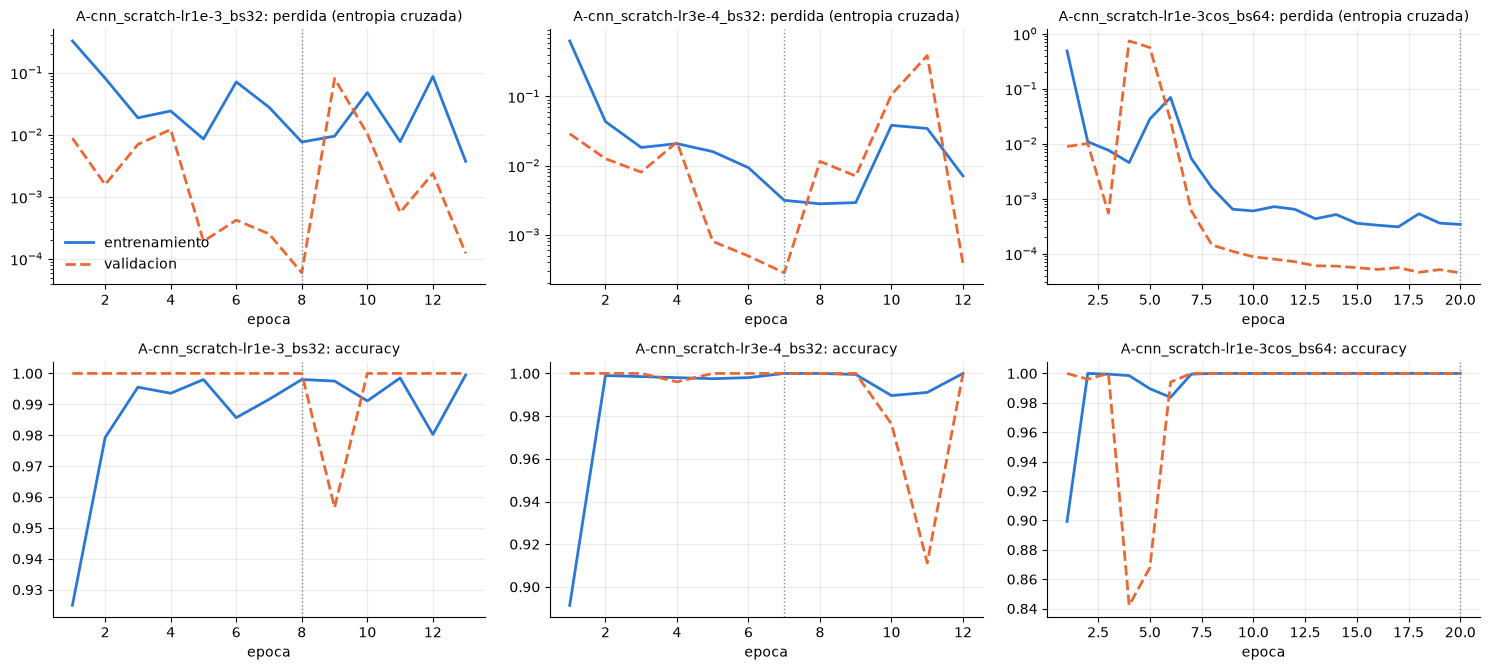

In [11]:
# Training and validation curves of each run
plot_curves(results_a, [("loss", "perdida (entropia cruzada)", True), ("acc", "accuracy", False)])
plt.show()

**Análisis.**

- **La clasificación se satura en la primera época.** Las tres corridas llegan a `val/acc` de 1.000 desde la época 1 y terminan con `test/acc` de 1.000. Distinguir entre las 10 categorías es trivial porque se diferencian por el color y la forma general, así que el accuracy no sirve para comparar las combinaciones.
- **La pérdida de validación tampoco separa las combinaciones.** Las mejores `val/loss` son 6.0e-5 (`lr1e-3_bs32`, época 8), 2.8e-4 (`lr3e-4_bs32`, época 7) y 4.5e-5 (`lr1e-3cos_bs64`, época 20). Con valores de ese orden el modelo ya asigna más del 99.99 % de probabilidad a la categoría correcta, y las diferencias entre corridas son ruido.
- **Con learning rate constante el entrenamiento es inestable.** La `val/loss` de `lr1e-3_bs32` salta de 6.0e-5 a 8.1e-2 en la época 9 (con `val/acc` de 0.957), y la de `lr3e-4_bs32` sube a 0.39 en la época 11 (`val/acc` de 0.911). La causa probable es que Adam da pasos de tamaño parecido al learning rate aunque el gradiente sea muy pequeño, de modo que cerca del mínimo sigue oscilando.
- **El coseno estabiliza el entrenamiento.** `lr1e-3cos_bs64` también tiene picos mientras el learning rate es alto (`val/loss` de 0.74 en la época 4), pero desde la época 7 la curva baja de forma monótona hasta 4.5e-5. Es la única corrida que completa sus 20 épocas sin activar `EarlyStopping`.
- **No hay sobreajuste.** Las pérdidas de entrenamiento y validación terminan en el mismo orden (por debajo de 1e-2 en las tres corridas). Las paradas tempranas de `lr1e-3_bs32` (época 13) y `lr3e-4_bs32` (época 12) se deben a las oscilaciones descritas arriba y no a que la validación empeore de forma sostenida. Con `min_delta` de 0 y pérdidas tan pequeñas, cualquier oscilación cuenta como empeoramiento.
- **El modelo A queda como línea base.** Como la tarea se resuelve con muy poca información de la imagen, no hay razones para esperar que el backbone aprenda los detalles finos que distinguen un defecto. La calidad del embedding se mide con el AUROC de detección de anomalías en `anomalias.ipynb`, donde el modelo A se compara con la misma red sin entrenar, con el modelo B y con el ResNet-18 preentrenado.

## 3. Modelo B, CNN destilada

Código en `src/models/distill.py`, configuración en `conf/model/cnn_distill.yaml` y combinaciones en `conf/experiment/cnn_distill/`.

### 3.1 Teacher: ResNet-18 preentrenado

*Pendiente.*

### 3.2 Técnica de destilado

*Pendiente.*

### 3.3 `LightningModule`

*Pendiente.*

### 3.4 Combinaciones de hiperparámetros

*Pendiente.*

### 3.5 Entrenamiento

*Pendiente.*

### 3.6 Resultados y análisis de overfitting

*Pendiente.*

## 4. Comparación de los modelos A y B

Parámetros, tiempo de inferencia y curvas de entrenamiento y validación del teacher, el modelo A y el modelo B.

*Pendiente.*